# Round 3: ImageNet CE + THINGS CE + CKA (monkey N)

**Loss** = 1 · CE_ImageNet + 1 · CE_THINGS + Σ weight · mean over bins of log(1 − CKA_S)
- CE_ImageNet: ImageNet train images (CordsNet's augmentation), true labels, ImageNet head (1000 classes).
- CE_THINGS: THINGS images of the 1306 concepts not in ImageNet, true labels, new THINGS head (initialized from the trained head: val top-1 accuracy 0.630). Overlapping concepts: no CE, CKA only.
- CKA_S targets: V1–layer2 (20–200 ms), V4–layer6 (50–200 ms), IT–layer8 (70–200 ms).

| run | CKA weights | epochs |
|---|---|---|
| R3 control | 0 (logged only) | 20 |
| R3 3 areas, w1 each | 1, 1, 1 | 20 |
| R3 3 areas, w1/3 each | 1/3, 1/3, 1/3 | 20 |

**Round 1–2 for comparison** (10 epochs, CE on pseudo-labels from the pretrained model, no ImageNet images, no THINGS head): R1 control, R2 3 areas w1 each, R2 3 areas w1/3 each.

Shared: batch 64 from one recording day (same batches in every run), AdamW lr 3e-5 cosine to 0, fp32, seed 2723. Evaluation on the val split: CKA_S pooled over batches of 64 (Round 1–2 protocol); THINGS head on all 1306 val images of non-overlapping concepts; ImageNet head on THINGS images of overlapping concepts; ImageNet-val (50,000 images, Resize 256 + CenterCrop 224) on the saved checkpoints. Accuracies are top-1 at the last step (200 ms) unless stated.

In [1]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

CN = Path("~/Desktop/DynVision/CordsNet").expanduser()
IMNET = CN / "Round3/outputs/imagenet_val"
r3_dir = {"R3 control": CN / "Round3/outputs/control",
          "R3 3 areas, w1 each": CN / "Round3/outputs/multi3_w1each",
          "R3 3 areas, w1/3 each": CN / "Round3/outputs/multi3_w0p33each"}
old_dir = {"R1 control": CN / "Round1/outputs/round1/control",
           "R2 3 areas, w1 each": CN / "Round2/outputs/multi3_w1each",
           "R2 3 areas, w1/3 each": CN / "Round2/outputs/multi3_w0p33each"}
r3_imnet = {"R3 control": "control", "R3 3 areas, w1 each": "multi3_w1each", "R3 3 areas, w1/3 each": "multi3_w0p33each"}
old_imnet = {"R1 control": "control", "R2 3 areas, w1 each": "multi3_w1each", "R2 3 areas, w1/3 each": "multi3_w0p33each"}
pair = {"R3 control": "R1 control", "R3 3 areas, w1 each": "R2 3 areas, w1 each", "R3 3 areas, w1/3 each": "R2 3 areas, w1/3 each"}
color = {"pretrained": "0.35", "R3 control": "#2a78d6", "R3 3 areas, w1 each": "#8e44ad", "R3 3 areas, w1/3 each": "#eb6834"}
for o, r in pair.items():
    color[r] = color[o]
targets = [("V1", "layer2", np.arange(2, 20)), ("V4", "layer6", np.arange(5, 20)), ("IT", "layer8", np.arange(7, 20))]
S = 1   # CKA_S in the estimator axis

# val metrics and evaluation arrays (all epochs) of every run
val, ev = {}, {}
for r, d in {**r3_dir, **old_dir}.items():
    val[r] = pd.read_csv(d / "val_metrics.csv")
    ev[r] = {int(p.stem.split("_")[1]): np.load(p) for p in sorted((d / "eval").glob("epoch_*.npz"))}
train = {r: pd.read_csv(d / "train_metrics.csv") for r, d in r3_dir.items()}

# Round 1 runs did not log THINGS accuracy during training: it was recomputed from the checkpoints
# (Round1/accuracy/eval_accuracy.py -> accuracy.npz). Same metric as in val_metrics.csv: the evaluation
# images (full day batches of 64, as in every run's evaluation), concepts that overlap ImageNet,
# correct if the last-step prediction is one of the concept's matched ImageNet classes.
eval_stim = ev["R3 control"][0]["eval_rows"] + 1                       # stim_idx of the evaluation images
for r in val:
    if "things_top1" in val[r].columns or r in r3_dir:
        continue
    acc = np.load(old_dir[r] / "accuracy.npz")
    matched = {str(c): [int(i) for i in str(m).split(";")] for c, m in zip(acc["overlap_concepts"], acc["overlap_idx"])}
    pos = {int(s): k for k, s in enumerate(acc["stim_idx"])}
    idx = np.array([pos[int(s)] for s in eval_stim])
    concept = [str(x) for x in acc["concept"][idx]]
    keep = np.array([c in matched for c in concept])
    top1_last = acc["top5"][:, idx, -1, 0]                               # (epoch, image)
    hit = np.array([[top1_last[e, k] in matched[concept[k]] for k in np.where(keep)[0]] for e in range(len(acc["epochs"]))])
    val[r]["things_top1"] = pd.Series(hit.mean(axis=1), index=acc["epochs"]).reindex(val[r]["epoch"]).values
    print(f"{r}: THINGS (ImageNet head) top-1 accuracy from accuracy.npz ({keep.sum()} overlapping-concept images)")
last = {r: max(ev[r]) for r in ev}
layers = [str(x) for x in ev["R3 control"][0]["layers"]]
areas = [str(x) for x in ev["R3 control"][0]["areas"]]

# window CKA_S of each target = mean over the target's bins of the pooled CKA_S
cka = {}
for r in ev:
    for a, l, b in targets:
        cka[(r, a)] = [np.nanmean(ev[r][e]["cka_pooled"][layers.index(l), areas.index(a), b, S]) for e in sorted(ev[r])]

# ImageNet-val: Round 3 checkpoints (epoch -> npz), Rounds 1-2 at their last epoch, pretrained
imnet = {r: {int(p.stem.split("epoch")[1]): np.load(p) for p in sorted(IMNET.glob(f"{f}_epoch*.npz"))} for r, f in r3_imnet.items()}
imnet_old = {r: np.load(IMNET / f"{f}.npz") for r, f in old_imnet.items()}
imnet_pre = np.load(IMNET / "pretrained.npz")
print({r: sorted(v) for r, v in imnet.items()}, "| last epochs:", last)

R1 control: THINGS (ImageNet head) top-1 accuracy from accuracy.npz (513 overlapping-concept images)
{'R3 control': [5, 10, 15, 20], 'R3 3 areas, w1 each': [5, 10, 15, 20], 'R3 3 areas, w1/3 each': [5, 10, 15, 20]} | last epochs: {'R3 control': 20, 'R3 3 areas, w1 each': 20, 'R3 3 areas, w1/3 each': 20, 'R1 control': 10, 'R2 3 areas, w1 each': 10, 'R2 3 areas, w1/3 each': 10}


## 1. Summary at the end of training

Round 3 at epoch 20, Rounds 1–2 at epoch 10. THINGS (ImageNet head): top-1 accuracy on THINGS val images of the 548 concepts that overlap ImageNet. THINGS (new head): top-1 accuracy and CE (steps 70–99) on the 1306 val images of non-overlapping concepts (Round 3 only).

In [2]:
rows = []
pre = {"model": "pretrained", "epoch": 0, "ImageNet-val top-1 accuracy": imnet_pre["top1_t"][-1],
       "THINGS (ImageNet head) top-1 accuracy": val["R3 control"]["imnet_head_things_top1"].iloc[0],
       "THINGS (new head) top-1 accuracy": val["R3 control"]["things_head_top1"].iloc[0],
       "THINGS (new head) CE": val["R3 control"]["things_head_ce"].iloc[0]}
pre.update({f"CKA_S {a}-{l}": cka[("R3 control", a)][0] for a, l, b in targets})
rows.append(pre)
for r3, o in pair.items():                              # Round 1-2 run, then the matching Round 3 run
    for r in (o, r3):
        v = val[r].iloc[-1]
        row = {"model": r, "epoch": last[r],
               "ImageNet-val top-1 accuracy": (imnet[r][max(imnet[r])]["top1_t"][-1] if r in imnet else imnet_old[r]["top1_t"][-1]),
               "THINGS (ImageNet head) top-1 accuracy": v["imnet_head_things_top1"] if r in r3_dir else v["things_top1"],
               "THINGS (new head) top-1 accuracy": v["things_head_top1"] if r in r3_dir else np.nan,
               "THINGS (new head) CE": v["things_head_ce"] if r in r3_dir else np.nan}
        row.update({f"CKA_S {a}-{l}": cka[(r, a)][-1] for a, l, b in targets})
        rows.append(row)
summary = pd.DataFrame(rows).set_index("model")
summary.round(4)

,epoch,ImageNet-val top-1 accuracy,THINGS (ImageNet head) top-1 accuracy,THINGS (new head) top-1 accuracy,THINGS (new head) CE,CKA_S V1-layer2,CKA_S V4-layer6,CKA_S IT-layer8
model,,,,,,,,
pretrained,0,0.5788,0.6959,0.6302,1.6956,0.2198,0.1054,0.1080
R1 control,10,0.5420,0.6784,NaN,NaN,0.2229,0.1102,0.1034
R3 control,20,0.6109,0.7212,0.6401,1.6411,0.2206,0.1073,0.0980
"R2 3 areas, w1 each",10,0.5045,0.6686,NaN,NaN,0.2707,0.3285,0.3468
"R3 3 areas, w1 each",20,0.6010,0.7037,0.6194,1.6872,0.2797,0.3996,0.3544
"R2 3 areas, w1/3 each",10,0.5171,0.6842,NaN,NaN,0.2528,0.1686,0.3086
"R3 3 areas, w1/3 each",20,0.6080,0.7193,0.6340,1.6597,0.2497,0.1869,0.3069


## 2. Round 2 vs Round 3: recognition

Same CKA setting side by side (Rounds 1–2: pseudo-label CE only; Round 3: ImageNet + THINGS CE). Dotted line: pretrained.

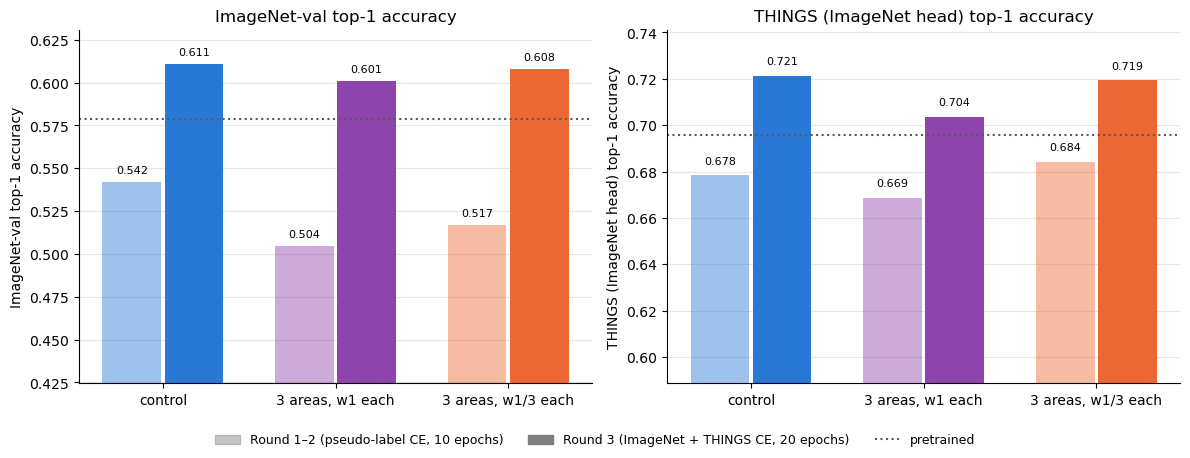

In [10]:
metrics = ["ImageNet-val top-1 accuracy", "THINGS (ImageNet head) top-1 accuracy"]
groups = ["control", "3 areas, w1 each", "3 areas, w1/3 each"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
x = np.arange(len(groups))
for ax, m in zip(axes, metrics):
    for i, (r3, o) in enumerate(pair.items()):          # pair: Round 3 run -> its Round 1-2 counterpart
        for dx, r, alpha in [(-0.18, o, 0.45), (0.18, r3, 1.0)]:
            v = summary.loc[r, m]
            ax.bar(i + dx, v, 0.34, color=color[r], alpha=alpha)
            ax.text(i + dx, v + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.axhline(summary.loc["pretrained", m], color=color["pretrained"], ls=":", lw=1.5)
    lo, hi = summary[m].min(), summary[m].max()
    ax.set(xticks=x, xticklabels=groups, ylabel=m, title=m, ylim=(lo - 0.08, hi + 0.02))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
# one legend below both panels (light = Round 1-2, dark = Round 3), so it never covers a bar
handles = [plt.Rectangle((0, 0), 1, 1, color="0.5", alpha=0.45), plt.Rectangle((0, 0), 1, 1, color="0.5"),
           plt.Line2D([], [], color=color["pretrained"], ls=":", lw=1.5)]
fig.legend(handles, ["Round 1–2 (pseudo-label CE, 10 epochs)", "Round 3 (ImageNet + THINGS CE, 20 epochs)", "pretrained"],
           loc="lower center", ncol=3, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

All round2 configurations are worse than baseline pretrained CordsNet (Round2 uses THINGS pseudo labels and no ImageNet CE); all round3 configurations are better than baseline pretrained CordsNet.

And still the more weights given to CKA terms, the more impact on (decreasing) accuracy.

Round3 trained for 20 epochs, round2 trained for 10 epochs; but doesn't really matter for accuracy comparisons because if we train round2 for more epochs accuracy will decrease even more.

## 3. Validation metrics over epochs

Solid: Round 3 (20 epochs). Dashed: Rounds 1–2 (10 epochs). Dotted: pretrained. Top: CKA_S per target. Bottom: THINGS (ImageNet head) top-1 accuracy; new THINGS head top-1 accuracy and CE (Round 3 only).

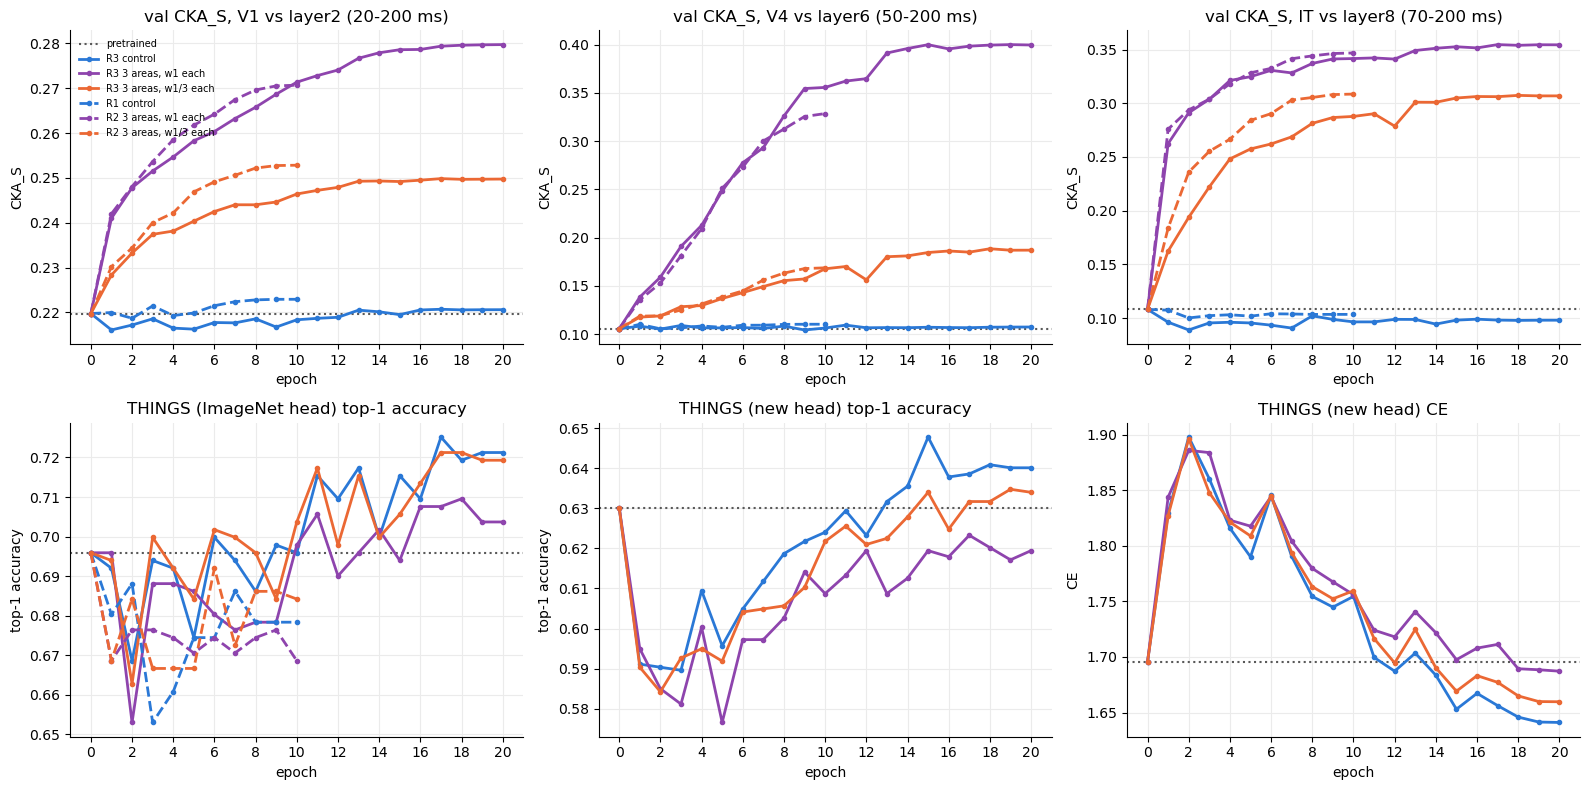

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (a, l, b) in zip(axes[0], targets):
    ax.axhline(cka[("R3 control", a)][0], color=color["pretrained"], ls=":", lw=1.5, label="pretrained")
    for r in ev:
        ax.plot(sorted(ev[r]), cka[(r, a)], "-o" if r in r3_dir else "--o", color=color[r], lw=2, ms=3, label=r)
    ax.set(title=f"val CKA_S, {a} vs {l} ({b[0] * 10}-200 ms)", xlabel="epoch", ylabel="CKA_S")
panels = [("THINGS (ImageNet head) top-1 accuracy", "imnet_head_things_top1", "things_top1"),
          ("THINGS (new head) top-1 accuracy", "things_head_top1", None),
          ("THINGS (new head) CE", "things_head_ce", None)]
for ax, (title, c3, cold) in zip(axes[1], panels):
    ax.axhline(val["R3 control"][c3].iloc[0], color=color["pretrained"], ls=":", lw=1.5)
    for r in val:
        if r in r3_dir:
            ax.plot(val[r]["epoch"], val[r][c3], "-o", color=color[r], lw=2, ms=3)
        elif cold:
            ax.plot(val[r]["epoch"], val[r][cold], "--o", color=color[r], lw=2, ms=3)
    ax.set(title=title, xlabel="epoch", ylabel=title.split(") ")[-1])
for ax in axes.flat:
    ax.set_xticks(range(0, 21, 2))
    ax.grid(color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

So including two loss terms did not interfere with CKA learning (w1/3 is slower). All three regions show signs of saturation by the 20th epoch; overall V4 clibmed to the highest validation CKA (0.4).

**Bottom Left**: THINGS' 548 overlapping categories images (in validation set only), accuracy computed using ImageNet classifier.

For all three accuracy/CE plots: control > w1/3 > w1.

## 4. ImageNet-val top-1 accuracy

Left: over training (Round 3 checkpoints at epochs 5, 10, 15, 20; Rounds 1–2 at their last epoch, epoch 10, as open markers). Right: over time after image onset, at the end of training (Round 3 solid, Rounds 1–2 dashed).

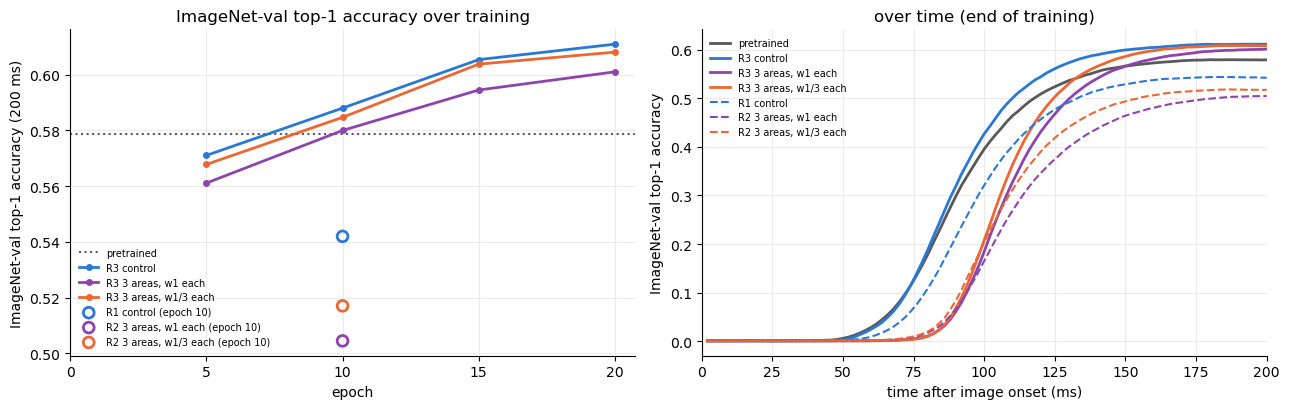

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.axhline(imnet_pre["top1_t"][-1], color=color["pretrained"], ls=":", lw=1.5, label="pretrained")
for r in r3_dir:
    ep = sorted(imnet[r])
    ax.plot(ep, [imnet[r][e]["top1_t"][-1] for e in ep], "-o", color=color[r], lw=2, ms=4, label=r)
for r in old_dir:
    ax.scatter([10], [imnet_old[r]["top1_t"][-1]], s=60, facecolor="none", edgecolor=color[r], lw=2, zorder=5, label=f"{r} (epoch 10)")
ax.set(xlabel="epoch", ylabel="ImageNet-val top-1 accuracy (200 ms)", title="ImageNet-val top-1 accuracy over training", xticks=[0, 5, 10, 15, 20])
ax = axes[1]
t_ms = imnet_pre["time_ms"]
ax.plot(t_ms, imnet_pre["top1_t"], color=color["pretrained"], lw=2, label="pretrained")
for r in r3_dir:
    ax.plot(t_ms, imnet[r][max(imnet[r])]["top1_t"], color=color[r], lw=2, label=r)
for r in old_dir:
    ax.plot(t_ms, imnet_old[r]["top1_t"], color=color[r], lw=1.5, ls="--", label=r)
ax.set(xlabel="time after image onset (ms)", ylabel="ImageNet-val top-1 accuracy", title="over time (end of training)", xlim=(0, 200))
for ax in axes:
    ax.grid(color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

I only computed ImageNet accuracy by the 5-th, 10-th, 15-th, and 20-th epochs; and for round 2 only last epoch accuracy was obtained.

## 5. THINGS (new head) top-1 accuracy over time

All 1306 val images of non-overlapping concepts. Epoch 0 = pretrained model + trained head.

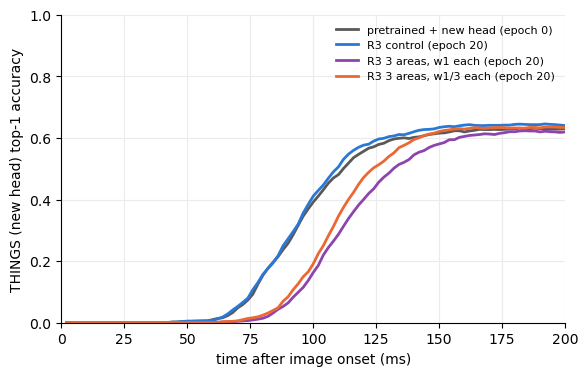

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
t_ms = (np.arange(len(ev["R3 control"][0]["things_head_top1_t"])) + 1) * 2
ax.plot(t_ms, ev["R3 control"][0]["things_head_top1_t"], color=color["pretrained"], lw=2, label="pretrained + new head (epoch 0)")
for r in r3_dir:
    ax.plot(t_ms, ev[r][last[r]]["things_head_top1_t"], color=color[r], lw=2, label=f"{r} (epoch {last[r]})")
ax.set(xlabel="time after image onset (ms)", ylabel="THINGS (new head) top-1 accuracy", xlim=(0, 200), ylim=(0, 1))
ax.grid(color="0.92")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.show()

## 6. Training curves (Round 3)

Per step, smoothed over 50 steps. Train CKA_S per target = mean over the target's bins (per batch). CE_ImageNet: ImageNet train batch (with augmentation); CE_THINGS: THINGS train images of non-overlapping concepts.

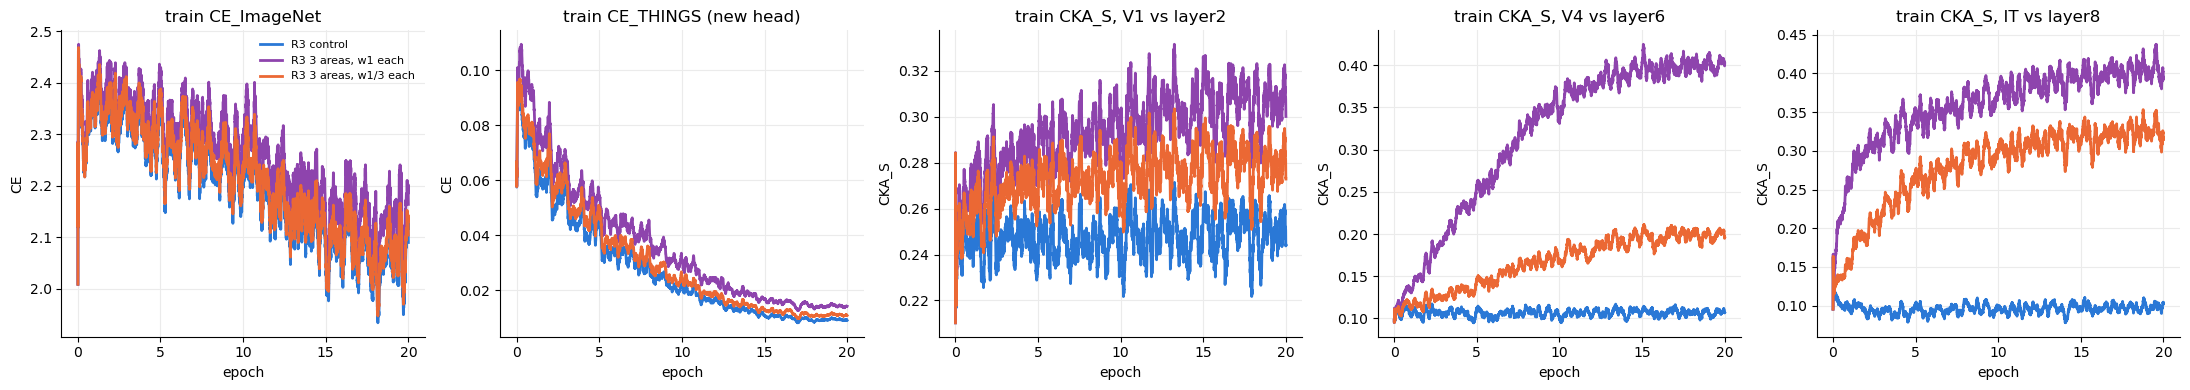

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for r in r3_dir:
    d = train[r]
    x = d["global_step"] / d.groupby("epoch")["step"].max().iloc[0]
    axes[0].plot(x, d["loss_ce_imagenet"].rolling(50, min_periods=1).mean(), color=color[r], lw=2, label=r)
    axes[1].plot(x, d["loss_ce_things"].rolling(50, min_periods=1).mean(), color=color[r], lw=2)
    for ax, (a, l, b) in zip(axes[2:], targets):
        cols = [f"cka_S_{a}_{l}_bin{k:02d}" for k in b]
        ax.plot(x, d[cols].mean(axis=1).rolling(50, min_periods=1).mean(), color=color[r], lw=2)
axes[0].set(title="train CE_ImageNet", ylabel="CE")
axes[1].set(title="train CE_THINGS (new head)", ylabel="CE")
for ax, (a, l, b) in zip(axes[2:], targets):
    ax.set(title=f"train CKA_S, {a} vs {l}", ylabel="CKA_S")
for ax in axes:
    ax.set(xlabel="epoch")
    ax.grid(color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## 7. CKA_S per 10 ms bin, end of training

Pooled CKA_S of each target's layer and area. Solid: Round 3; dashed: Rounds 1–2; dotted: pretrained. Gray: the target's bins.

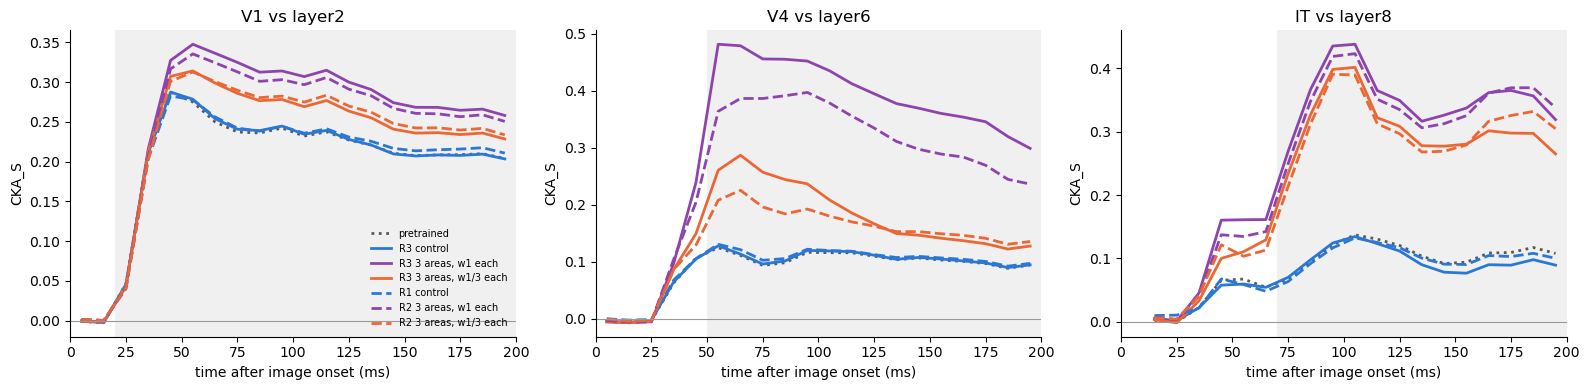

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
t_bin = np.arange(20) * 10 + 5
for ax, (a, l, b) in zip(axes, targets):
    i, j = layers.index(l), areas.index(a)
    ax.axvspan(b[0] * 10, 200, color="0.94", lw=0)
    ax.plot(t_bin, ev["R3 control"][0]["cka_pooled"][i, j, :, S], ":", color=color["pretrained"], lw=2, label="pretrained")
    for r in ev:
        ax.plot(t_bin, ev[r][last[r]]["cka_pooled"][i, j, :, S], "-" if r in r3_dir else "--", color=color[r], lw=2, label=r)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.set(title=f"{a} vs {l}", xlabel="time after image onset (ms)", ylabel="CKA_S", xlim=(0, 200))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

## 8. Layer x area CKA_S, end of training

Mean over each area's window of the pooled CKA_S. Black boxes: aligned targets. Top: pretrained and Round 2; bottom: Round 3.

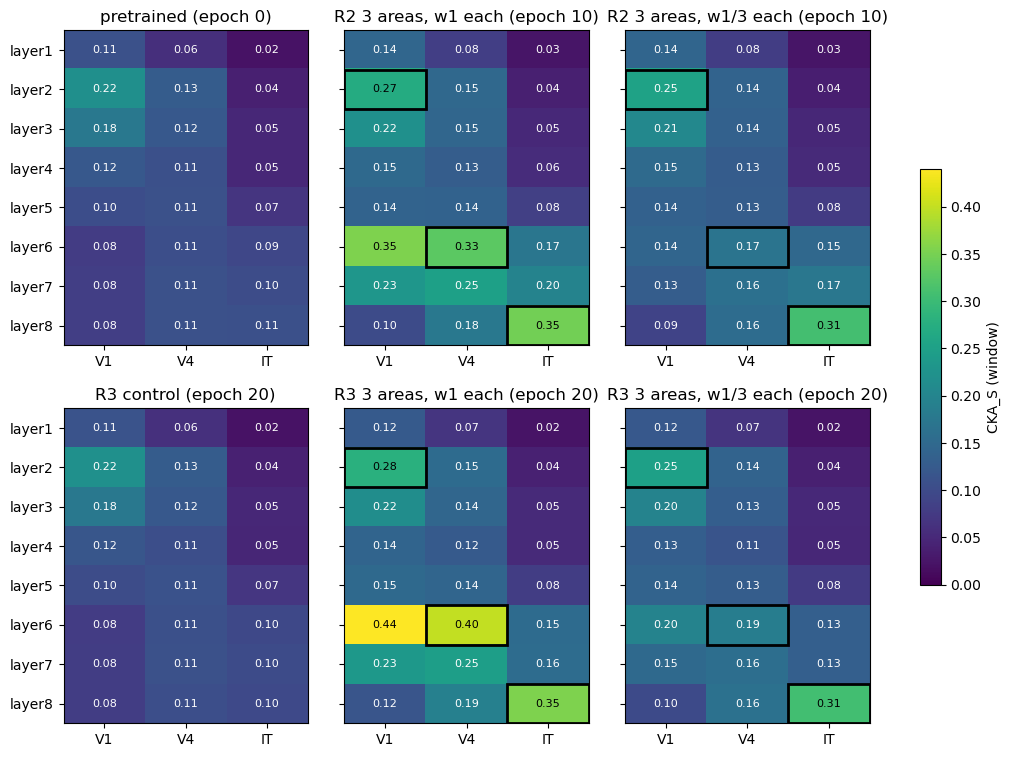

In [9]:
grid = [["pretrained", "R2 3 areas, w1 each", "R2 3 areas, w1/3 each"],
        ["R3 control", "R3 3 areas, w1 each", "R3 3 areas, w1/3 each"]]
win = {a: b for a, l, b in targets}
mats = {}
for row in grid:
    for r in row:
        e = ev["R3 control"][0] if r == "pretrained" else ev[r][last[r]]
        mats[r] = np.array([[np.nanmean(e["cka_pooled"][i, j, win[a], S]) for j, a in enumerate(areas)] for i in range(len(layers))])
vmax = max(np.nanmax(m) for m in mats.values())
fig, axes = plt.subplots(2, 3, figsize=(13, 9), gridspec_kw={"wspace": 0.15})
for row, axrow in zip(grid, axes):
    for r, ax in zip(row, axrow):
        im = ax.imshow(mats[r], cmap="viridis", vmin=0, vmax=vmax, aspect="auto")
        for i in range(len(layers)):
            for j in range(len(areas)):
                ax.text(j, i, f"{mats[r][i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if mats[r][i, j] < 0.6 * vmax else "black")
        if r != "pretrained" and r != "R3 control":
            for a, l, b in targets:
                ax.add_patch(plt.Rectangle((areas.index(a) - 0.5, layers.index(l) - 0.5), 1, 1, fill=False, ec="k", lw=2))
        ax.set(xticks=range(len(areas)), xticklabels=areas, yticks=range(len(layers)),
               yticklabels=layers if ax in axes[:, 0] else [],
               title=r + (" (epoch 0)" if r == "pretrained" else f" (epoch {last[r]})"))
fig.colorbar(im, ax=axes, shrink=0.6, label="CKA_S (window)")
plt.show()